# Analisis Perbandingan Kinerja Algoritma Machine Learning untuk Klasifikasi Keamanan Air Minum Menggunakan SVM, Random Forest, dan XGBoost

**Mini Project**

**Tujuan.** Memprediksi apakah sampel air aman diminum (`is_safe`: 1 = aman, 0 = tidak aman) dari 20 fitur kandungan zat kimia dan mikroorganisme.

**Alur kerja notebook**

1. Analisis data dan preprocessing (cek tipe data, missing value, duplikat, outlier, distribusi, korelasi, split train/test)
2. Pemilihan algoritma dan alasannya
3. Pelatihan dan tuning hyperparameter (SVM, Random Forest, XGBoost)
4. Evaluasi dengan metrik yang sesuai dan perbandingan model
5. Pemilihan model terbaik dan kesimpulan

In [ ]:
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report,
                             roc_curve, precision_recall_curve)
from xgboost import XGBClassifier

try:
    from IPython.display import display
except ImportError:
    display = print

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

In [ ]:
DATA_PATH = "waterQuality1.csv"
df_raw = pd.read_csv(DATA_PATH)
print("Ukuran data (baris, kolom):", df_raw.shape)
df_raw.head()

Ukuran data (baris, kolom): (7999, 21)


,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,is_safe
0,1.65,9.08,0.04,2.85,0.007,0.35,0.83,0.17,0.05,0.20,...,0.054,16.08,1.13,0.007,37.75,6.78,0.08,0.34,0.02,1
1,2.32,21.16,0.01,3.31,0.002,5.28,0.68,0.66,0.90,0.65,...,0.100,2.01,1.93,0.003,32.26,3.21,0.08,0.27,0.05,1
2,1.01,14.02,0.04,0.58,0.008,4.24,0.53,0.02,0.99,0.05,...,0.078,14.16,1.11,0.006,50.28,7.07,0.07,0.44,0.01,0
3,1.36,11.33,0.04,2.96,0.001,7.23,0.03,1.66,1.08,0.71,...,0.016,1.41,1.29,0.004,9.12,1.72,0.02,0.45,0.05,1
4,0.92,24.33,0.03,0.20,0.006,2.67,0.69,0.57,0.61,0.13,...,0.117,6.74,1.11,0.003,16.90,2.41,0.02,0.06,0.02,1


---
# 1. Analisis Data dan Preprocessing

## 1.1 Struktur data dan tipe data

In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7999 entries, 0 to 7998
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   aluminium    7999 non-null   float64
 1   ammonia      7999 non-null   object 
 2   arsenic      7999 non-null   float64
 3   barium       7999 non-null   float64
 4   cadmium      7999 non-null   float64
 5   chloramine   7999 non-null   float64
 6   chromium     7999 non-null   float64
 7   copper       7999 non-null   float64
 8   flouride     7999 non-null   float64
 9   bacteria     7999 non-null   float64
 10  viruses      7999 non-null   float64
 11  lead         7999 non-null   float64
 12  nitrates     7999 non-null   float64
 13  nitrites     7999 non-null   float64
 14  mercury      7999 non-null   float64
 15  perchlorate  7999 non-null   float64
 16  radium       7999 non-null   float64
 17  selenium     7999 non-null   float64
 18  silver       7999 non-null   float64
 19  uraniu

**Temuan.** Kolom `ammonia` dan `is_safe` terbaca sebagai teks (`object`/`str`), padahal seharusnya numerik. Ini tanda ada nilai yang tidak valid di dalamnya. Kita cari nilainya.

In [ ]:
for col in ["ammonia", "is_safe"]:
    bad = pd.to_numeric(df_raw[col], errors="coerce").isna()
    print(f"{col:8s} -> nilai non-numerik: {df_raw.loc[bad, col].unique()} | jumlah baris: {bad.sum()}")

print("\nBaris yang bermasalah:")
df_raw[pd.to_numeric(df_raw["ammonia"], errors="coerce").isna()]

ammonia  -> nilai non-numerik: ['#NUM!'] | jumlah baris: 3
is_safe  -> nilai non-numerik: ['#NUM!'] | jumlah baris: 3

Baris yang bermasalah:


,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,is_safe
7551,0.03,#NUM!,0.08,0.79,0.07,0.08,0.05,0.58,0.34,0.00,...,0.183,4.37,1.43,0.007,0.62,2.54,0.07,0.05,0.05,#NUM!
7568,0.06,#NUM!,0.07,1.72,0.08,0.32,0.01,1.11,0.61,0.00,...,0.178,12.10,2.03,0.008,1.37,2.05,0.06,0.10,0.07,#NUM!
7890,0.01,#NUM!,0.08,0.49,0.00,0.07,0.09,0.06,0.72,0.57,...,0.088,9.57,1.45,0.009,7.67,7.70,0.03,0.05,0.02,#NUM!


**Temuan.** Ada 3 baris dengan nilai `#NUM!` (galat bawaan Excel) pada `ammonia` **dan** `is_safe` sekaligus. Karena label (`is_safe`) ikut hilang, baris ini tidak bisa dipakai untuk melatih maupun menguji model, sehingga dihapus. Setelah itu, seluruh kolom diubah ke tipe numerik.

In [ ]:
df = df_raw.apply(pd.to_numeric, errors="coerce")   # '#NUM!' menjadi NaN
df = df.dropna(subset=["is_safe"]).copy()           # buang baris tanpa label
df["is_safe"] = df["is_safe"].astype(int)

print("Ukuran data setelah dibersihkan:", df.shape)
print("Baris dibuang:", len(df_raw) - len(df))

Ukuran data setelah dibersihkan: (7996, 21)
Baris dibuang: 3


## 1.2 Missing value dan duplikat

In [ ]:
missing = df.isna().sum()
print("Tabel 1. Jumlah missing value per kolom (hanya yang > 0)")
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing value.")

n_dup = df.duplicated().sum()
print(f"\nJumlah baris duplikat: {n_dup}")
df = df.drop_duplicates().reset_index(drop=True)
print("Ukuran data akhir:", df.shape)

Tabel 1. Jumlah missing value per kolom (hanya yang > 0)
Tidak ada missing value.

Jumlah baris duplikat: 0
Ukuran data akhir: (7996, 21)


**Interpretasi.** Setelah 3 baris `#NUM!` dibuang, tidak ada missing value maupun baris duplikat yang tersisa, jadi tidak diperlukan imputasi.

## 1.3 Nilai tidak valid (negatif)

Konsentrasi zat tidak mungkin bernilai negatif. Kita periksa apakah ada fitur yang memiliki nilai di bawah 0.

In [ ]:
features = [c for c in df.columns if c != "is_safe"]

neg_counts = (df[features] < 0).sum()
print("Tabel 2. Jumlah nilai negatif per fitur (hanya yang > 0)")
display(neg_counts[neg_counts > 0].to_frame("jumlah_negatif"))

print("\nNilai negatif pada ammonia:", sorted(df.loc[df["ammonia"] < 0, "ammonia"].unique().tolist()))

Tabel 2. Jumlah nilai negatif per fitur (hanya yang > 0)


,jumlah_negatif
ammonia,10



Nilai negatif pada ammonia: [-0.08, -0.07, -0.03, -0.01]


**Temuan dan keputusan.** Hanya `ammonia` yang memiliki nilai negatif: 10 baris (sekitar 0,13%) dengan nilai antara -0,08 dan -0,01. Nilainya sangat kecil, sehingga kemungkinan besar derau pengukuran di sekitar nol (di bawah batas deteksi). Nilai ini **dibulatkan ke 0** (*clip*) alih-alih membuang baris. Aturan ini bersifat tetap (tidak dipelajari dari data), sehingga aman dilakukan sebelum split dan tidak menyebabkan kebocoran data.

In [ ]:
df[features] = df[features].clip(lower=0)
print("Nilai minimum ammonia setelah clip:", df["ammonia"].min())

Nilai minimum ammonia setelah clip: 0.0


## 1.4 Statistik deskriptif

In [ ]:
print("Tabel 3. Statistik deskriptif seluruh fitur (setelah pembersihan)")
display(df.describe().T.round(4))

Tabel 3. Statistik deskriptif seluruh fitur (setelah pembersihan)


,count,mean,std,min,25%,50%,75%,max
aluminium,7996.0,0.6664,1.2653,0.0,0.0400,0.070,0.2800,5.05
ammonia,7996.0,14.2783,8.8788,0.0,6.5775,14.130,22.1325,29.84
arsenic,7996.0,0.1615,0.2526,0.0,0.0300,0.050,0.1000,1.05
barium,7996.0,1.5679,1.2162,0.0,0.5600,1.190,2.4825,4.94
cadmium,7996.0,0.0428,0.0360,0.0,0.0080,0.040,0.0700,0.13
chloramine,7996.0,2.1776,2.5672,0.0,0.1000,0.530,4.2400,8.68
chromium,7996.0,0.2473,0.2707,0.0,0.0500,0.090,0.4400,0.90
copper,7996.0,0.8059,0.6536,0.0,0.0900,0.750,1.3900,2.00
flouride,7996.0,0.7716,0.4354,0.0,0.4075,0.770,1.1600,1.50
bacteria,7996.0,0.3197,0.3295,0.0,0.0000,0.220,0.6100,1.00


**Interpretasi.** Skala antar fitur sangat berbeda (misalnya `perchlorate` mencapai sekitar 60, sedangkan `mercury` maksimum sekitar 0,01). Kondisi ini tidak masalah bagi model berbasis pohon (Random Forest, XGBoost), tetapi **SVM sangat sensitif terhadap skala** sehingga fitur harus distandarisasi untuk SVM (dilakukan di dalam *pipeline*, lihat 1.9).

## 1.5 Distribusi variabel target

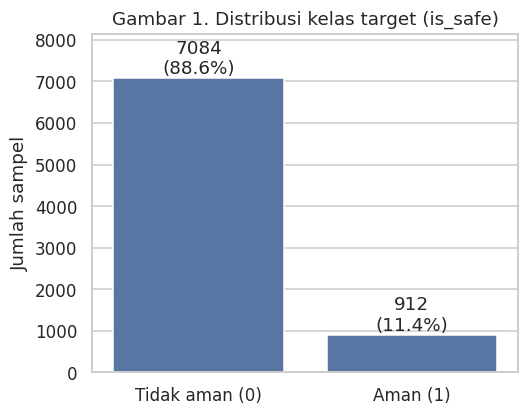

Akurasi jika selalu menebak kelas mayoritas: 0.8859


In [ ]:
counts = df["is_safe"].value_counts().sort_index()
props = df["is_safe"].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=["Tidak aman (0)", "Aman (1)"], y=counts.values, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v}\n({props.values[i]*100:.1f}%)", ha="center", va="bottom")
ax.set_title("Gambar 1. Distribusi kelas target (is_safe)")
ax.set_ylabel("Jumlah sampel")
ax.set_ylim(0, counts.max() * 1.15)
plt.show()

baseline_acc = props.max()
print(f"Akurasi jika selalu menebak kelas mayoritas: {baseline_acc:.4f}")

**Interpretasi.** Data **tidak seimbang**: sekitar 88,6% sampel adalah kelas 0 (tidak aman) dan hanya sekitar 11,4% kelas 1 (aman). Model yang selalu menebak "tidak aman" sudah memperoleh akurasi sekitar 88,6% tanpa belajar apa pun. Konsekuensinya:

- **Accuracy bukan metrik utama**, karena menyembunyikan kegagalan pada kelas minoritas. Metrik utama kita adalah **F1, precision, recall, dan PR-AUC** untuk kelas 1.
- Pembagian data memakai **stratifikasi** agar proporsi kelas sama di train dan test.
- Ketidakseimbangan ditangani di level model (`class_weight` untuk SVM dan Random Forest, `scale_pos_weight` untuk XGBoost), tanpa mengubah data uji.

## 1.6 Distribusi fitur

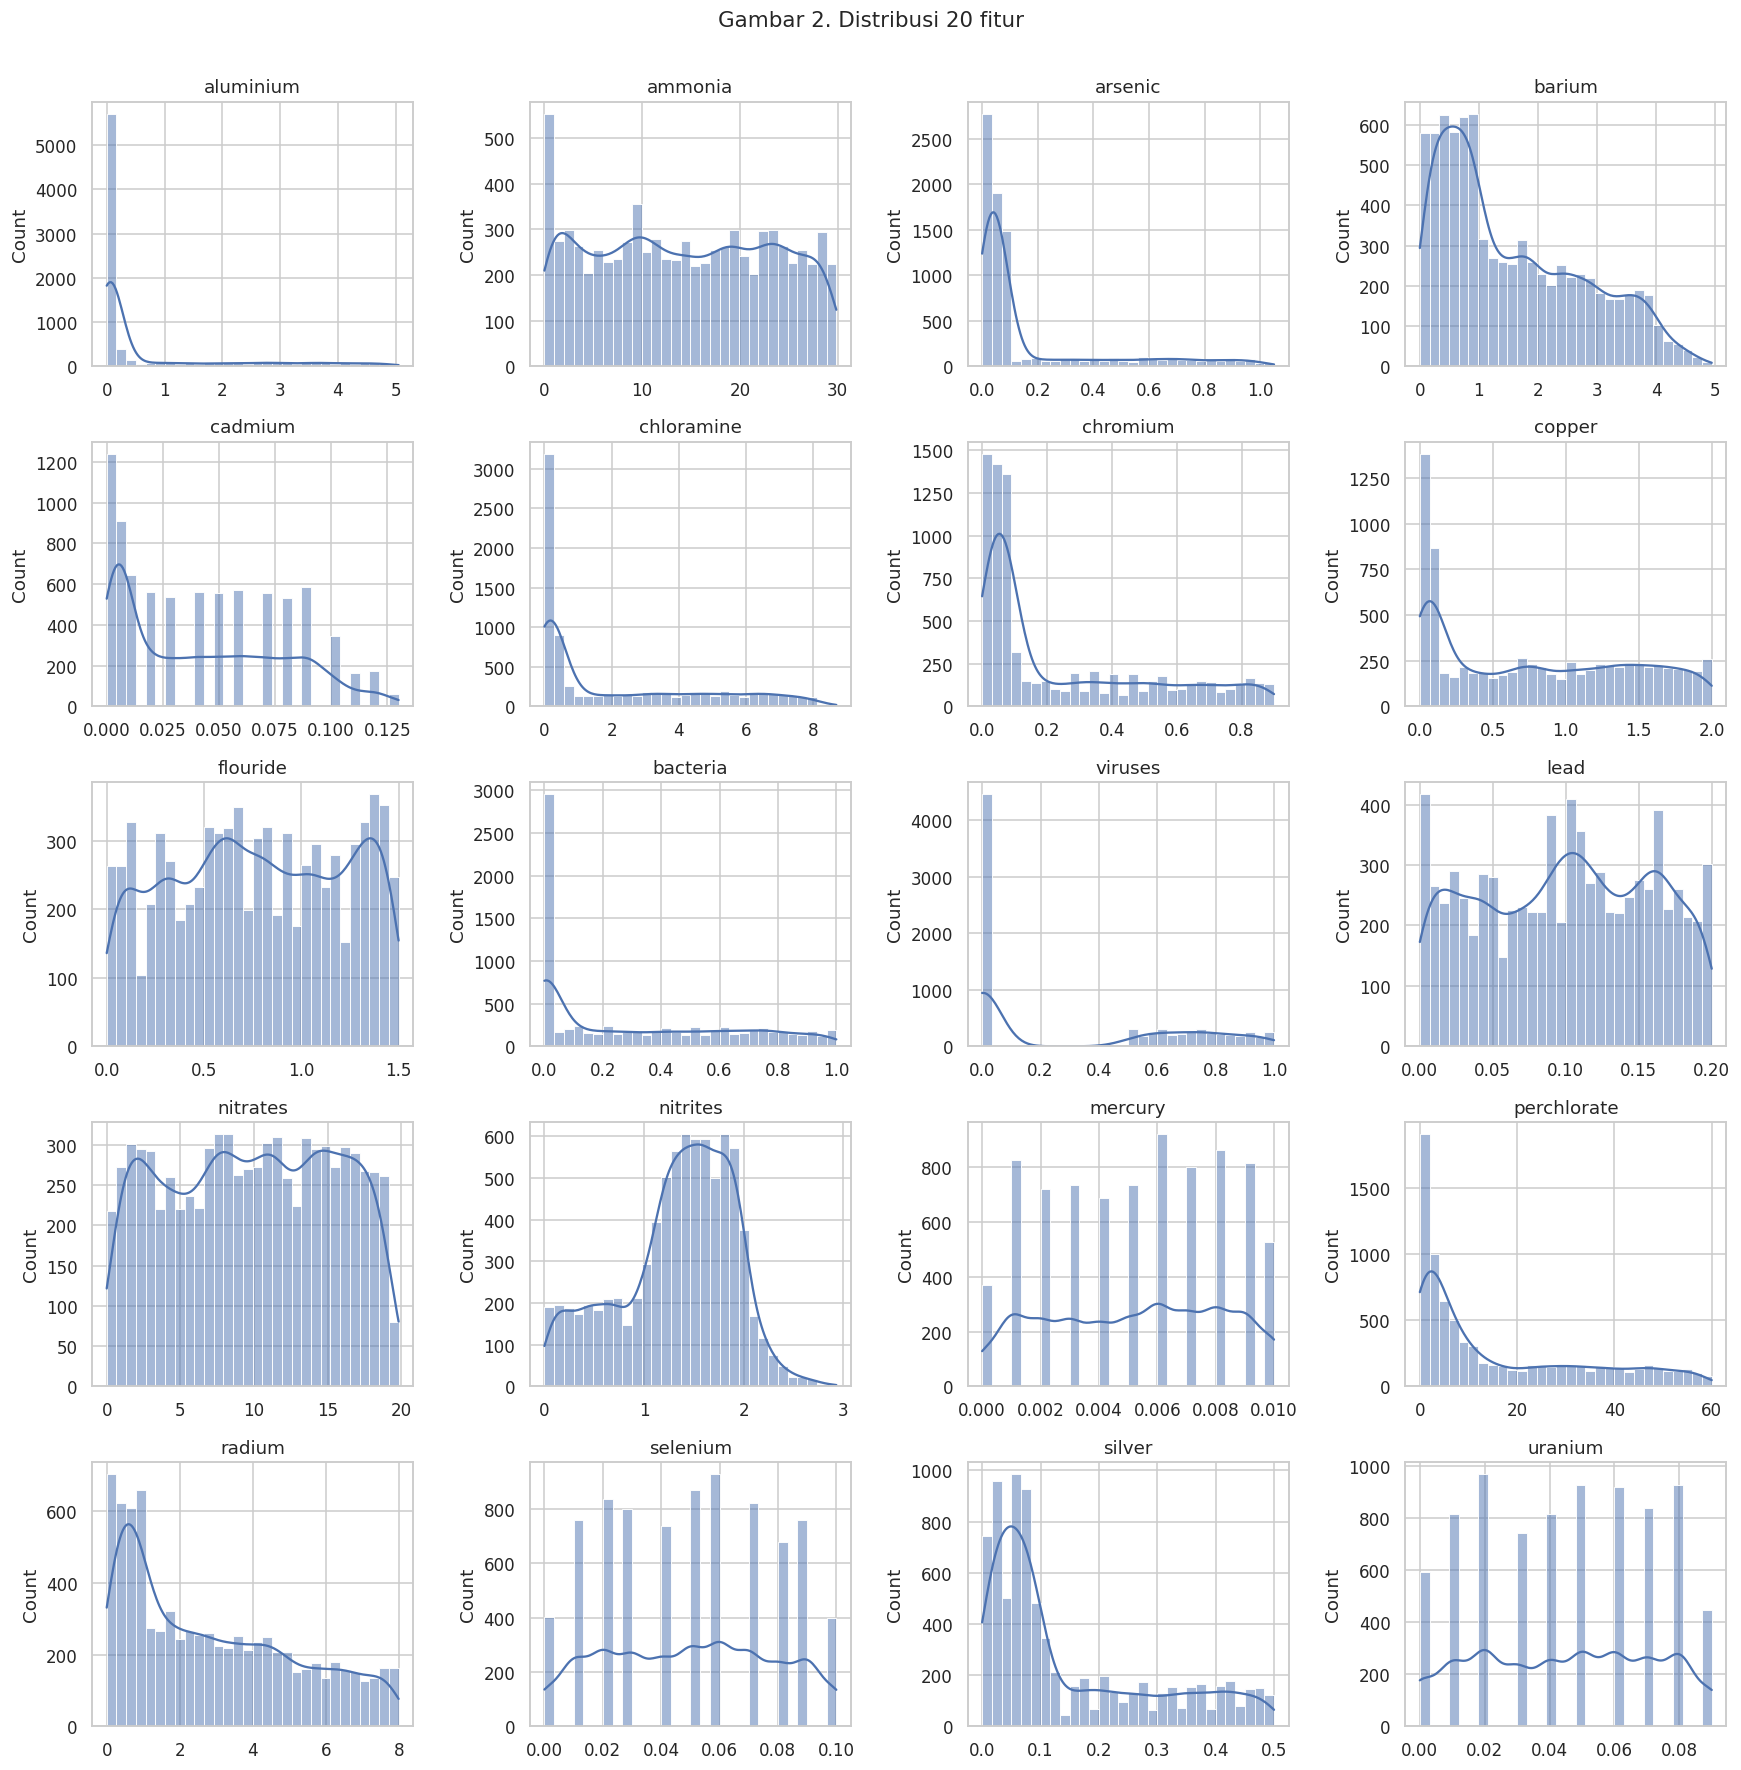

Tabel 4. Skewness fitur (urut dari terbesar)


,skewness
aluminium,2.01
arsenic,1.99
silver,1.03
chromium,1.03
perchlorate,0.94
chloramine,0.89
barium,0.66
bacteria,0.55
radium,0.55
cadmium,0.48


In [ ]:
fig, axes = plt.subplots(5, 4, figsize=(16, 16))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Gambar 2. Distribusi 20 fitur", y=1.005, fontsize=14)
plt.tight_layout()
plt.show()

skew = df[features].skew().sort_values(ascending=False)
print("Tabel 4. Skewness fitur (urut dari terbesar)")
display(skew.round(2).to_frame("skewness"))

**Interpretasi.** Bentuk distribusi fitur beragam dan sebagian besar **tidak berbentuk lonceng (normal)**:

- 16 dari 20 fitur memiliki |skewness| di bawah 1, tetapi banyak di antaranya tersebar relatif merata (mendekati seragam), misalnya `ammonia`, `flouride`, `lead`, `nitrates`, `mercury`, `selenium`, dan `uranium`. Hanya `nitrites` yang mendekati lonceng.
- `aluminium` dan `arsenic` sangat miring ke kanan (skewness sekitar 2); `chromium` dan `silver` miring sedang (sekitar 1).
- `bacteria` dan `viruses` memiliki lonjakan di nilai 0 (sekitar 35% dan 16% baris, artinya tidak terdeteksi), dan `viruses` terlihat bimodal (kelompok di 0 dan kelompok di 0,5 sampai 1).

Karena distribusinya tidak normal, kita tidak mengandalkan asumsi distribusi tertentu; model berbasis pohon tidak membutuhkannya, dan SVM RBF cukup dengan standardisasi.

## 1.7 Deteksi outlier

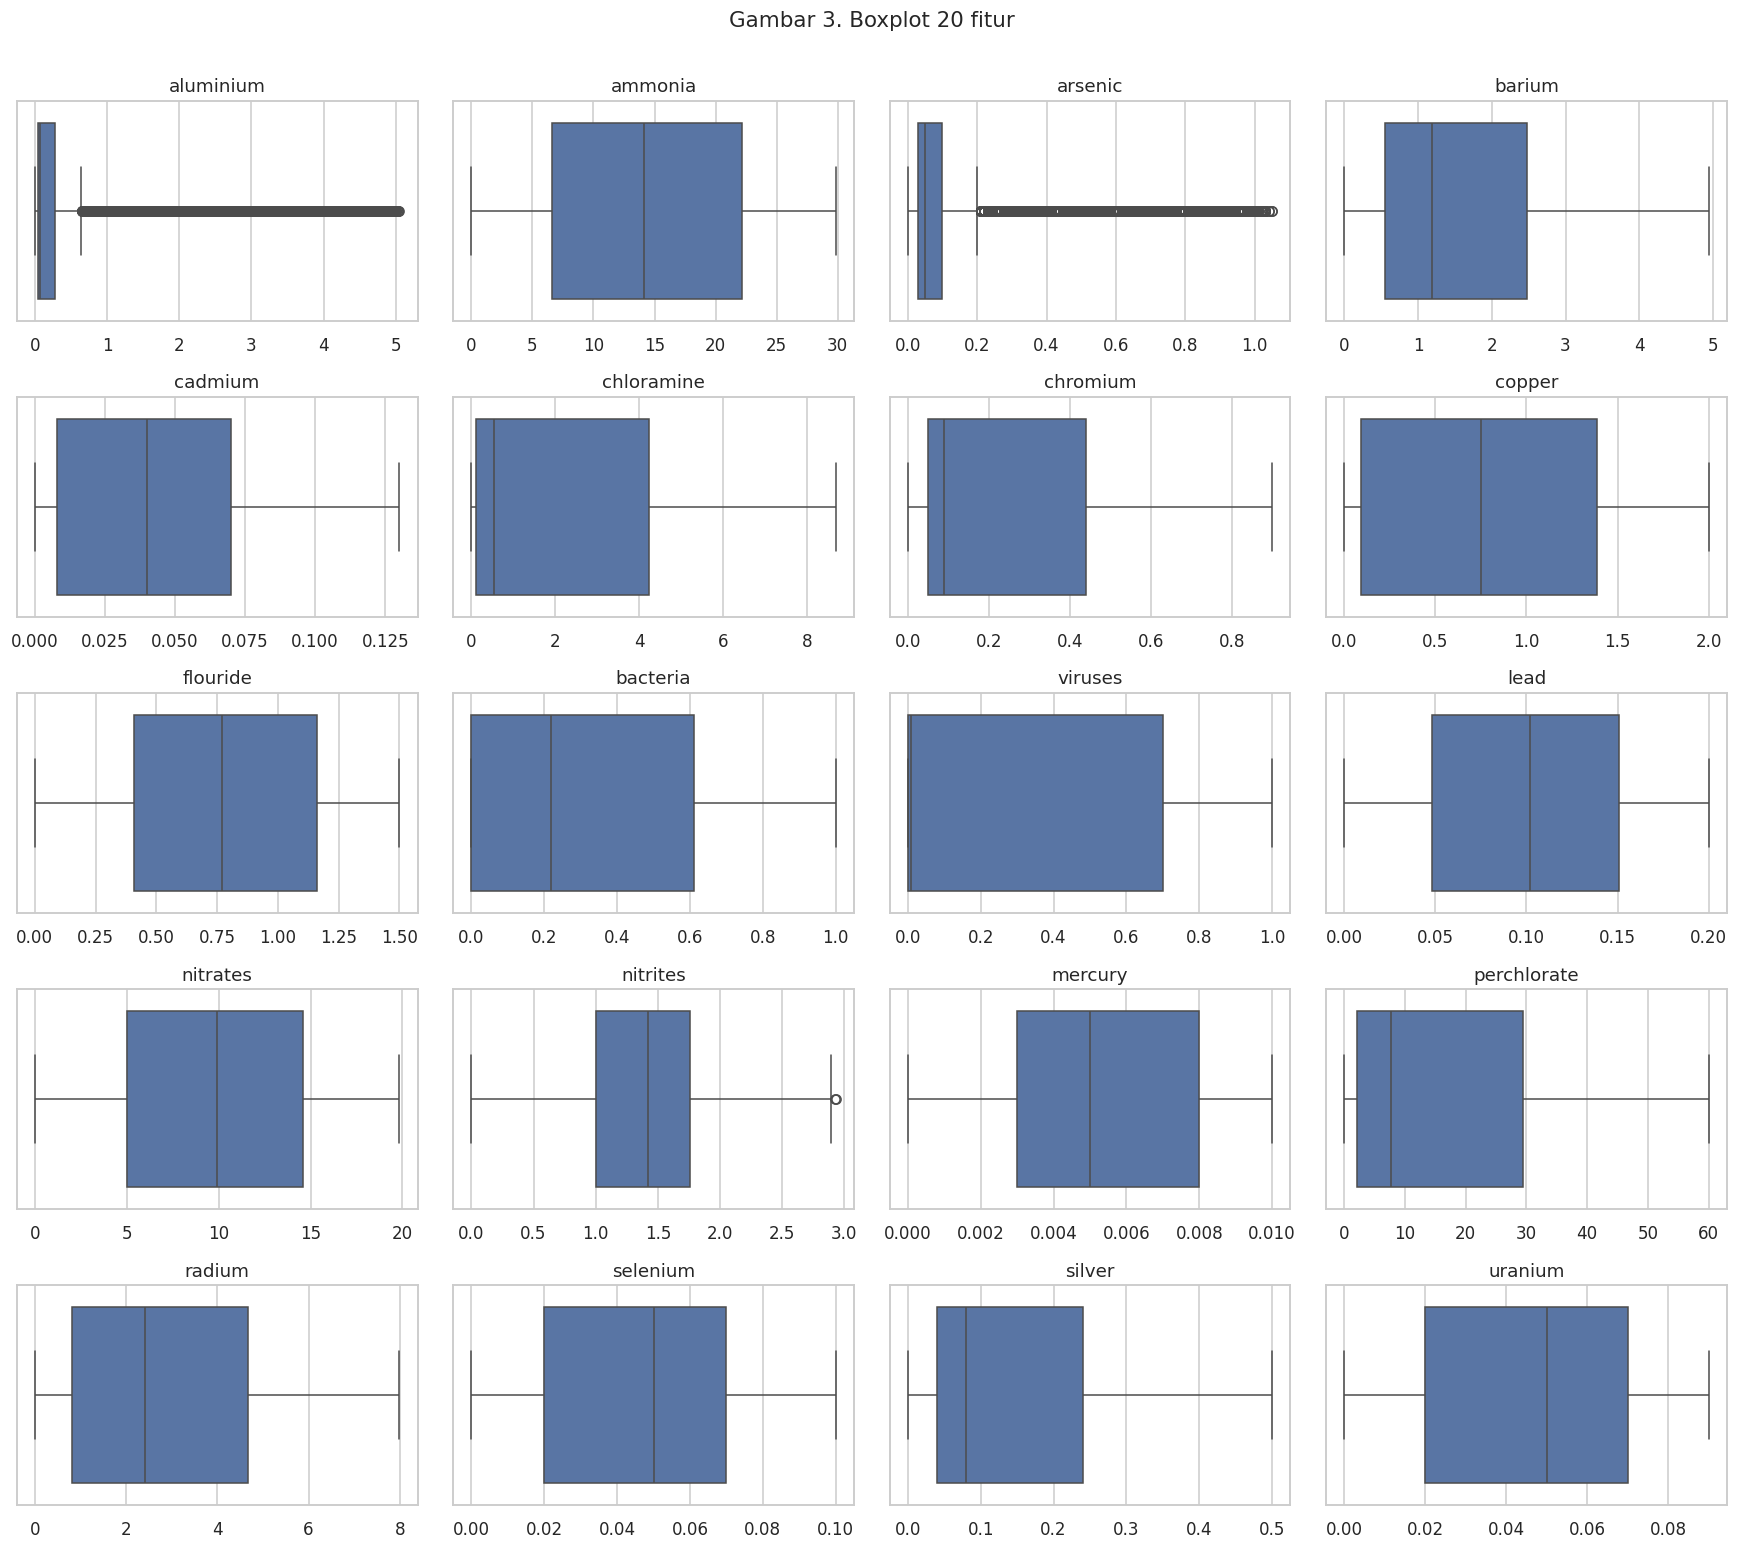

Tabel 5. Jumlah outlier per fitur (aturan IQR 1,5x), fitur dengan outlier saja


,jumlah_outlier,persen
aluminium,1731,21.65
arsenic,1634,20.44
nitrites,2,0.03


In [ ]:
fig, axes = plt.subplots(5, 4, figsize=(16, 14))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Gambar 3. Boxplot 20 fitur", y=1.005, fontsize=14)
plt.tight_layout()
plt.show()

def count_iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

outliers = pd.DataFrame({"jumlah_outlier": df[features].apply(count_iqr_outliers)})
outliers["persen"] = (outliers["jumlah_outlier"] / len(df) * 100).round(2)
print("Tabel 5. Jumlah outlier per fitur (aturan IQR 1,5x), fitur dengan outlier saja")
display(outliers[outliers["jumlah_outlier"] > 0].sort_values("persen", ascending=False))

**Interpretasi dan keputusan.** Berdasarkan aturan IQR, outlier hanya berarti pada `aluminium` dan `arsenic` (masing-masing sekitar 20% dari baris). `nitrites` hanya memiliki 2 outlier (0,03%), dan 17 fitur lain tidak memiliki outlier. Outlier **tidak dihapus** dengan alasan:

1. Proporsinya besar (20%); menghapusnya berarti membuang banyak data.
2. Ini adalah nilai pengukuran nyata dari distribusi yang miring ke kanan, bukan kesalahan input. Kadar kontaminan yang tinggi justru bisa menjadi sinyal penting untuk keamanan air.
3. Random Forest dan XGBoost tidak terpengaruh oleh outlier karena memisahkan data dengan ambang (*threshold*). Untuk SVM, standardisasi dilakukan di dalam pipeline.

## 1.8 Korelasi antar fitur dan dengan target

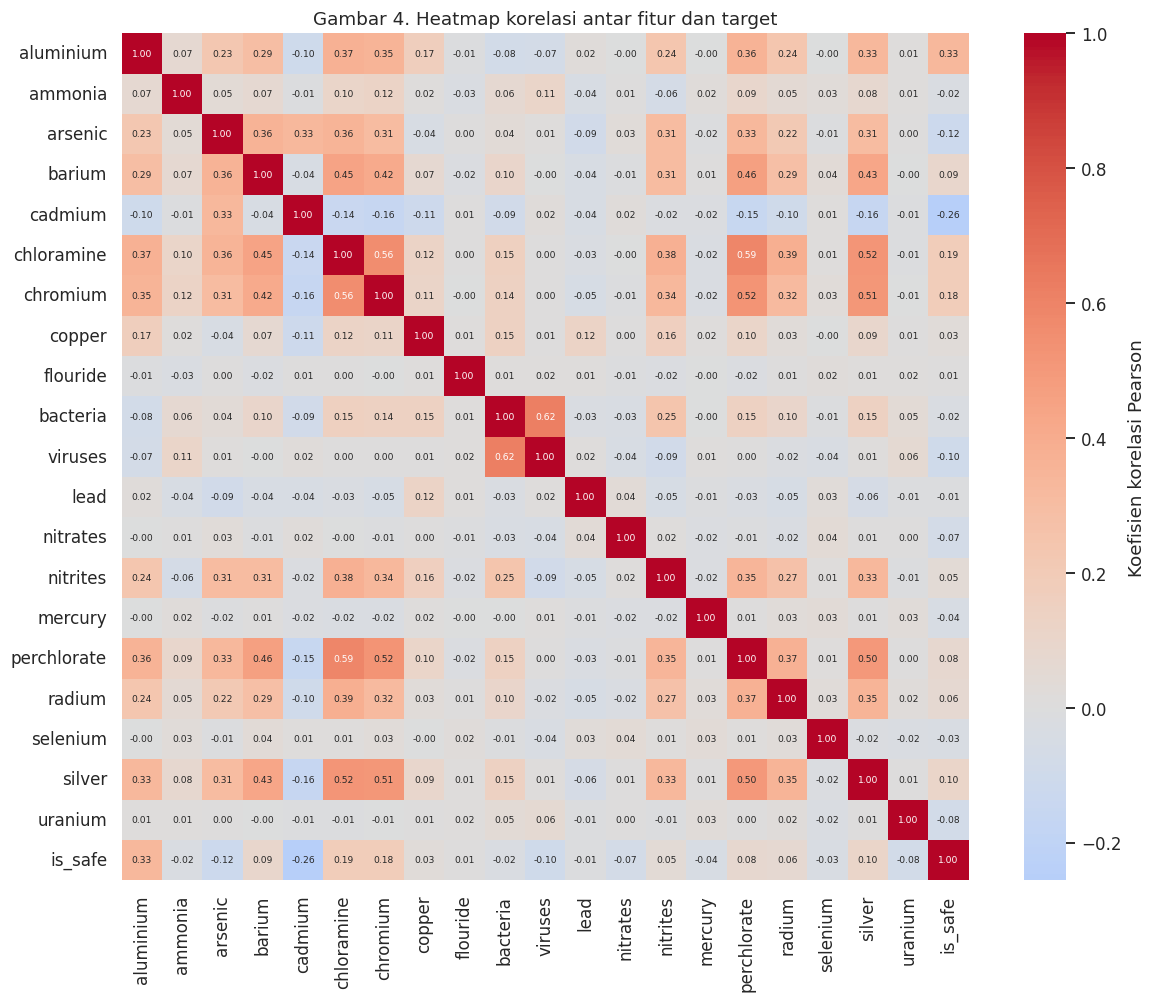

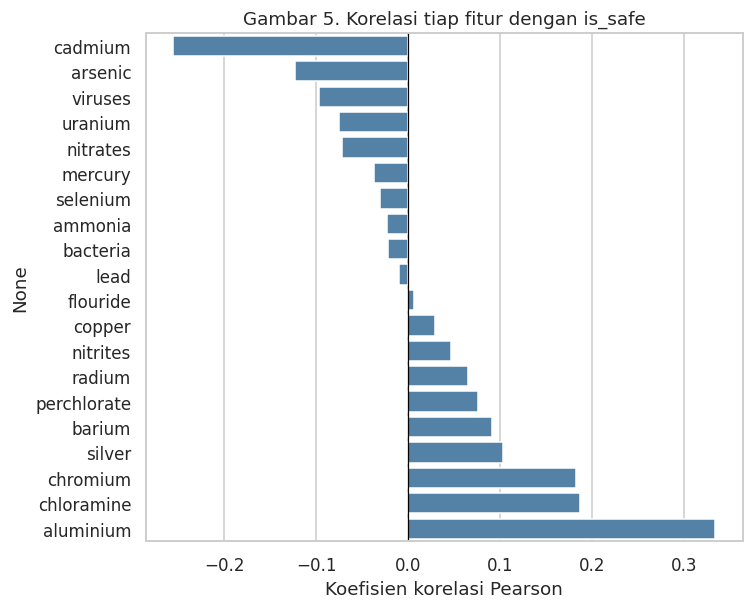

Tabel 6. Lima pasangan fitur dengan korelasi (absolut) tertinggi


|r|
bacteria   viruses      0.619
chloramine perchlorate  0.589
           chromium     0.556
chromium   perchlorate  0.524
chloramine silver       0.522

In [ ]:
corr = df.corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 6}, cmap="coolwarm", center=0, square=True,
            cbar_kws={"label": "Koefisien korelasi Pearson"})
plt.title("Gambar 4. Heatmap korelasi antar fitur dan target")
plt.show()

target_corr = corr["is_safe"].drop("is_safe").sort_values()
plt.figure(figsize=(7, 6))
sns.barplot(x=target_corr.values, y=target_corr.index, color="steelblue")
plt.axvline(0, color="black", lw=0.8)
plt.title("Gambar 5. Korelasi tiap fitur dengan is_safe")
plt.xlabel("Koefisien korelasi Pearson")
plt.show()

pairs = (corr.drop(index="is_safe", columns="is_safe").abs()
         .where(np.triu(np.ones((len(features), len(features)), dtype=bool), 1)).stack()
         .sort_values(ascending=False).head(5))
print("Tabel 6. Lima pasangan fitur dengan korelasi (absolut) tertinggi")
display(pairs.round(3).to_frame("|r|"))

**Interpretasi.**

- **Korelasi dengan target semuanya lemah** (|r| maksimum sekitar 0,33; terbesar `aluminium`, lalu `cadmium` yang negatif). Artinya tidak ada satu fitur pun yang cukup untuk memisahkan kelas; hubungan kemungkinan berupa kombinasi atau non-linear. Ini alasan memakai model non-linear (SVM RBF, ensemble pohon) dan bukan hanya regresi linear.
- **Tidak ada multikolinearitas serius**: korelasi antar fitur tertinggi hanya sekitar 0,62 (`bacteria` dan `viruses`). Semua fitur dipertahankan.

## 1.9 Split data train/test

Data dibagi 80% latih dan 20% uji dengan `stratify=y` agar proporsi kelas terjaga. Data uji **tidak disentuh** selama tuning (tuning memakai cross-validation pada data latih saja).

Standardisasi untuk SVM dimasukkan ke dalam `Pipeline` sehingga `StandardScaler` hanya di-*fit* pada data latih (di setiap lipatan CV), sehingga tidak terjadi kebocoran data (*data leakage*).

In [ ]:
X = df[features]
y = df["is_safe"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

split_info = pd.DataFrame({
    "jumlah_sampel": [len(X_train), len(X_test)],
    "kelas_0": [(y_train == 0).sum(), (y_test == 0).sum()],
    "kelas_1": [(y_train == 1).sum(), (y_test == 1).sum()],
    "persen_kelas_1": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["Train", "Test"]).round(2)
print("Tabel 7. Ukuran dan proporsi kelas setelah split")
display(split_info)

Tabel 7. Ukuran dan proporsi kelas setelah split


,jumlah_sampel,kelas_0,kelas_1,persen_kelas_1
Train,6396,5666,730,11.41
Test,1600,1418,182,11.38


---
# 2. Pemilihan Algoritma

Tiga algoritma klasifikasi dengan karakter berbeda dipilih agar perbandingan bermakna:

| Algoritma | Alasan dipilih | Penanganan kelas tidak seimbang | Hyperparameter yang dituning |
|---|---|---|---|
| **SVM (kernel RBF)** | Mampu membentuk batas keputusan non-linear; cocok untuk data numerik berdimensi menengah (20 fitur) dan jumlah sampel ribuan. Butuh standardisasi. | `class_weight="balanced"` | `C`, `gamma` |
| **Random Forest** | Ensemble pohon (*bagging*) yang stabil, tahan outlier, tidak butuh scaling, dan memberi *feature importance*. | `class_weight="balanced_subsample"` | `n_estimators`, `max_depth`, `min_samples_leaf` |
| **XGBoost** | Gradient boosting yang biasanya sangat kuat pada data tabular; membangun pohon secara bertahap untuk memperbaiki kesalahan sebelumnya. | `scale_pos_weight` = jumlah kelas 0 / jumlah kelas 1 | `n_estimators`, `max_depth`, `learning_rate` |

Sebagai pembanding (*sanity check*) ditambahkan **baseline** yang selalu menebak kelas mayoritas. Model yang dibuat harus jelas lebih baik daripada baseline ini pada metrik yang relevan.

**Metrik pemilihan hyperparameter:** F1-score kelas 1 pada 5-fold *Stratified* Cross-Validation, karena F1 menyeimbangkan precision dan recall pada kelas minoritas.

---
# 3. Pelatihan dan Tuning Hyperparameter

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

n_neg, n_pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = n_neg / n_pos
print(f"scale_pos_weight untuk XGBoost = {scale_pos_weight:.2f}")

search_space = {
    "SVM": (
        Pipeline([("scaler", StandardScaler()),
                  ("clf", SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE))]),
        {"clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.1]},
    ),
    "Random Forest": (
        RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=1),
        {"n_estimators": [200, 400], "max_depth": [None, 10, 20], "min_samples_leaf": [1, 2]},
    ),
    "XGBoost": (
        XGBClassifier(objective="binary:logistic", eval_metric="logloss",
                      scale_pos_weight=scale_pos_weight, subsample=0.8, colsample_bytree=0.8,
                      random_state=RANDOM_STATE, n_jobs=1),
        {"n_estimators": [200, 400], "max_depth": [3, 5, 7], "learning_rate": [0.05, 0.1]},
    ),
}

searches = {}
for name, (estimator, grid) in search_space.items():
    start = time.time()
    gs = GridSearchCV(estimator, grid, scoring="f1", cv=cv, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    searches[name] = gs
    print(f"{name:14s} | CV F1 terbaik = {gs.best_score_:.4f} | waktu = {time.time() - start:5.1f}s")
    print(f"{'':14s} | parameter terbaik: {gs.best_params_}")

scale_pos_weight untuk XGBoost = 7.76
SVM            | CV F1 terbaik = 0.6939 | waktu =  25.3s
               | parameter terbaik: {'clf__C': 10, 'clf__gamma': 'scale'}
Random Forest  | CV F1 terbaik = 0.7994 | waktu = 191.0s
               | parameter terbaik: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
XGBoost        | CV F1 terbaik = 0.8591 | waktu =  35.3s
               | parameter terbaik: {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 400}


Model dengan parameter terbaik sudah dilatih ulang pada seluruh data latih (`refit=True`). Langkah berikutnya mengevaluasi ketiga model pada data uji yang belum pernah dilihat.

---
# 4. Evaluasi Model

## 4.1 Metrik yang dipakai dan alasannya

Kelas positif adalah **1 = aman**.

| Metrik | Arti pada kasus ini | Mengapa dipakai |
|---|---|---|
| **Precision (kelas 1)** | Dari semua sampel yang diprediksi "aman", berapa yang benar-benar aman | Kesalahan paling berbahaya adalah air tidak aman diprediksi aman (*false positive*). Precision rendah berarti risiko itu tinggi. |
| **Recall (kelas 1)** | Dari semua sampel yang sebenarnya aman, berapa yang berhasil dikenali | Recall rendah berarti banyak air aman yang ditolak (kerugian efisiensi, bukan keselamatan). |
| **F1 (kelas 1)** | Rata-rata harmonik precision dan recall | Ringkasan tunggal yang jujur untuk kelas minoritas. Dipakai sebagai metrik utama. |
| **ROC-AUC** | Kemampuan memisahkan kedua kelas di semua ambang | Tidak bergantung pada ambang keputusan 0,5. |
| **PR-AUC** (*average precision*) | Kualitas ranking untuk kelas minoritas di semua ambang | Lebih sensitif daripada ROC-AUC pada data tidak seimbang. Nilai acak = proporsi kelas 1 (sekitar 0,11). |
| **Accuracy** | Proporsi tebakan benar | Hanya sebagai pembanding terhadap baseline; menyesatkan bila berdiri sendiri. |

Confusion matrix dipakai untuk melihat jenis kesalahan secara langsung.

In [ ]:
def get_score(model, X_):
    """Skor kontinu kelas 1 (probabilitas bila ada, selain itu decision_function) untuk ROC/PR."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_)[:, 1]
    return model.decision_function(X_)

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

fitted = {"Baseline (mayoritas)": baseline}
fitted.update({name: gs.best_estimator_ for name, gs in searches.items()})

rows = {}
preds, scores = {}, {}
for name, model in fitted.items():
    y_pred = model.predict(X_test)
    y_score = get_score(model, X_test)
    preds[name], scores[name] = y_pred, y_score
    rows[name] = {
        "CV F1 (train)": searches[name].best_score_ if name in searches else np.nan,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_score),
        "PR-AUC": average_precision_score(y_test, y_score),
    }

comparison = pd.DataFrame(rows).T
print("Tabel 8. Perbandingan kinerja model pada data uji (kelas positif = 1 / aman)")
display(comparison.round(4))

Tabel 8. Perbandingan kinerja model pada data uji (kelas positif = 1 / aman)


,CV F1 (train),Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Baseline (mayoritas),NaN,0.8862,0.0000,0.0000,0.0000,0.5000,0.1138
SVM,0.6939,0.9288,0.6753,0.7198,0.6968,0.9581,0.7791
Random Forest,0.7994,0.9600,0.9275,0.7033,0.8000,0.9766,0.9120
XGBoost,0.8591,0.9675,0.8736,0.8352,0.8539,0.9838,0.9384


**Cara membaca Tabel 8.**

- Bandingkan **Accuracy** model dengan baseline: selisihnya menunjukkan seberapa banyak model benar-benar belajar, bukan sekadar menebak kelas mayoritas.
- **Precision dan Recall** menunjukkan jenis kesalahan: precision rendah berarti banyak air tidak aman lolos sebagai "aman"; recall rendah berarti banyak air aman ditolak.
- Selisih besar antara **CV F1 (train)** dan **F1 (test)** menandakan *overfitting* atau variasi data; selisih kecil menandakan model stabil.

## 4.2 Confusion matrix

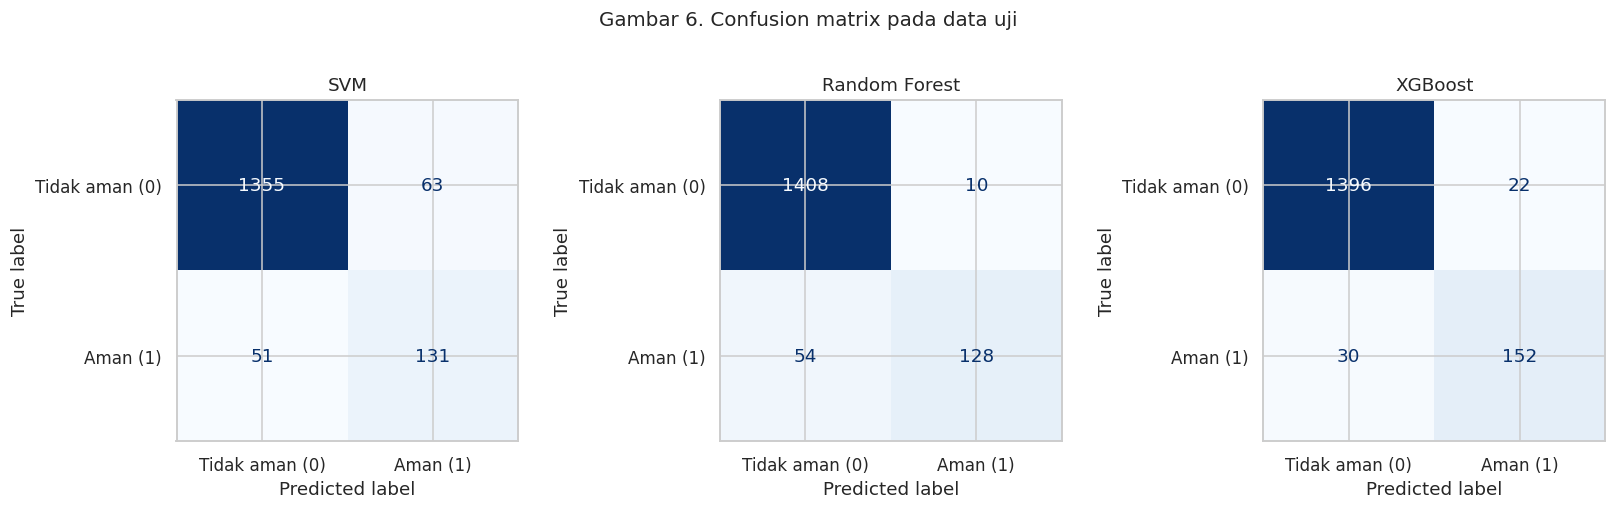

SVM            | benar-tidak-aman=1355 | air tidak aman lolos jadi 'aman' (FP)= 63 | air aman ditolak (FN)= 51 | benar-aman=131
Random Forest  | benar-tidak-aman=1408 | air tidak aman lolos jadi 'aman' (FP)= 10 | air aman ditolak (FN)= 54 | benar-aman=128
XGBoost        | benar-tidak-aman=1396 | air tidak aman lolos jadi 'aman' (FP)= 22 | air aman ditolak (FN)= 30 | benar-aman=152


In [ ]:
model_names = list(searches.keys())
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, name in zip(axes, model_names):
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds[name], display_labels=["Tidak aman (0)", "Aman (1)"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
fig.suptitle("Gambar 6. Confusion matrix pada data uji", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

for name in model_names:
    tn, fp, fn, tp = confusion_matrix(y_test, preds[name]).ravel()
    print(f"{name:14s} | benar-tidak-aman={tn:4d} | air tidak aman lolos jadi 'aman' (FP)={fp:3d} | "
          f"air aman ditolak (FN)={fn:3d} | benar-aman={tp:3d}")

**Interpretasi.** Pada setiap panel, baris adalah label sebenarnya dan kolom adalah prediksi. Sel **kanan-atas** (*false positive*) adalah air tidak aman yang salah dinyatakan aman, yaitu kesalahan paling berbahaya. Sel **kiri-bawah** (*false negative*) adalah air aman yang ditolak. Model terbaik adalah yang menekan kedua sel ini, dengan prioritas pada *false positive*.

## 4.3 Classification report per model

In [ ]:
for name in model_names:
    print(f"=== {name} ===")
    print(classification_report(y_test, preds[name], target_names=["Tidak aman (0)", "Aman (1)"], digits=4))

=== SVM ===
                precision    recall  f1-score   support

Tidak aman (0)     0.9637    0.9556    0.9596      1418
      Aman (1)     0.6753    0.7198    0.6968       182

      accuracy                         0.9287      1600
     macro avg     0.8195    0.8377    0.8282      1600
  weighted avg     0.9309    0.9287    0.9297      1600

=== Random Forest ===
                precision    recall  f1-score   support

Tidak aman (0)     0.9631    0.9929    0.9778      1418
      Aman (1)     0.9275    0.7033    0.8000       182

      accuracy                         0.9600      1600
     macro avg     0.9453    0.8481    0.8889      1600
  weighted avg     0.9590    0.9600    0.9576      1600

=== XGBoost ===
                precision    recall  f1-score   support

Tidak aman (0)     0.9790    0.9845    0.9817      1418
      Aman (1)     0.8736    0.8352    0.8539       182

      accuracy                         0.9675      1600
     macro avg     0.9263    0.9098    0.9178 

## 4.4 Kurva ROC dan Precision-Recall

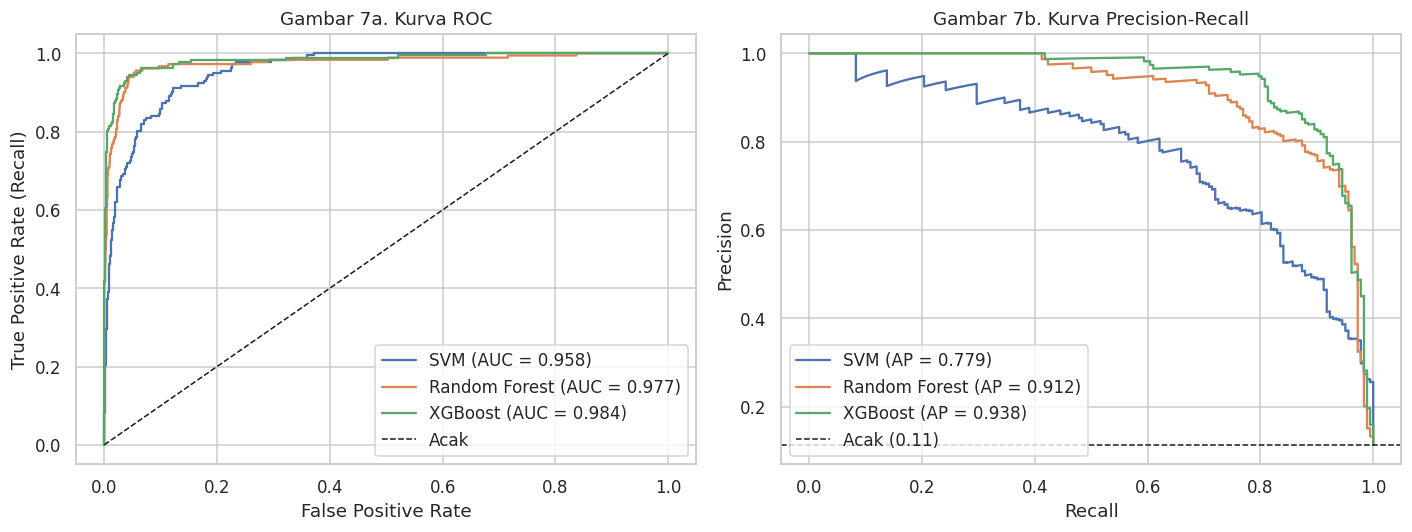

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name in model_names:
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {comparison.loc[name, 'ROC-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Acak")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].set_title("Gambar 7a. Kurva ROC")
axes[0].legend(loc="lower right")

for name in model_names:
    prec, rec, _ = precision_recall_curve(y_test, scores[name])
    axes[1].plot(rec, prec, label=f"{name} (AP = {comparison.loc[name, 'PR-AUC']:.3f})")
axes[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Acak ({y_test.mean():.2f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Gambar 7b. Kurva Precision-Recall")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.show()

**Interpretasi.** Kurva yang lebih dekat ke sudut kiri-atas (ROC) atau kanan-atas (PR) menandakan model lebih baik. Pada data tidak seimbang, **kurva PR lebih informatif** karena langsung memperlihatkan trade-off precision dan recall untuk kelas minoritas. Garis putus-putus pada kurva PR adalah kinerja tebakan acak (sama dengan proporsi kelas 1).

## 4.5 Perbandingan visual antar model

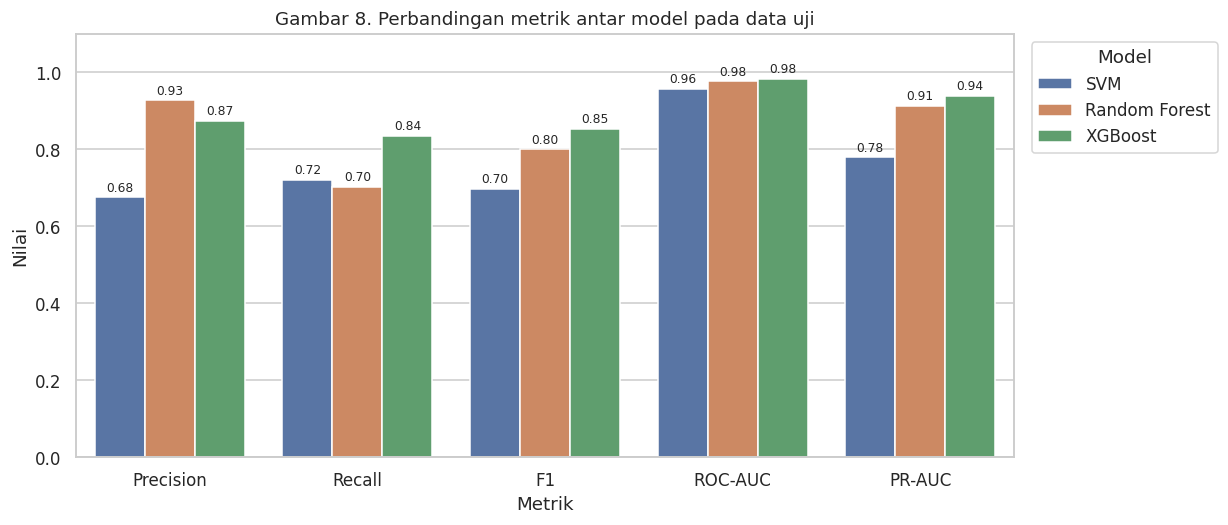

In [ ]:
plot_metrics = ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
plot_df = comparison.loc[model_names, plot_metrics].reset_index().melt(
    id_vars="index", var_name="Metrik", value_name="Nilai").rename(columns={"index": "Model"})

plt.figure(figsize=(11, 5))
ax = sns.barplot(data=plot_df, x="Metrik", y="Nilai", hue="Model")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
plt.ylim(0, 1.1)
plt.legend(title="Model", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.title("Gambar 8. Perbandingan metrik antar model pada data uji")
plt.show()

## 4.6 Fitur yang paling berpengaruh

Random Forest dan XGBoost memakai *feature importance* bawaan; untuk SVM (RBF tidak punya koefisien per fitur) dipakai *permutation importance* pada data uji (penurunan F1 saat fitur diacak).

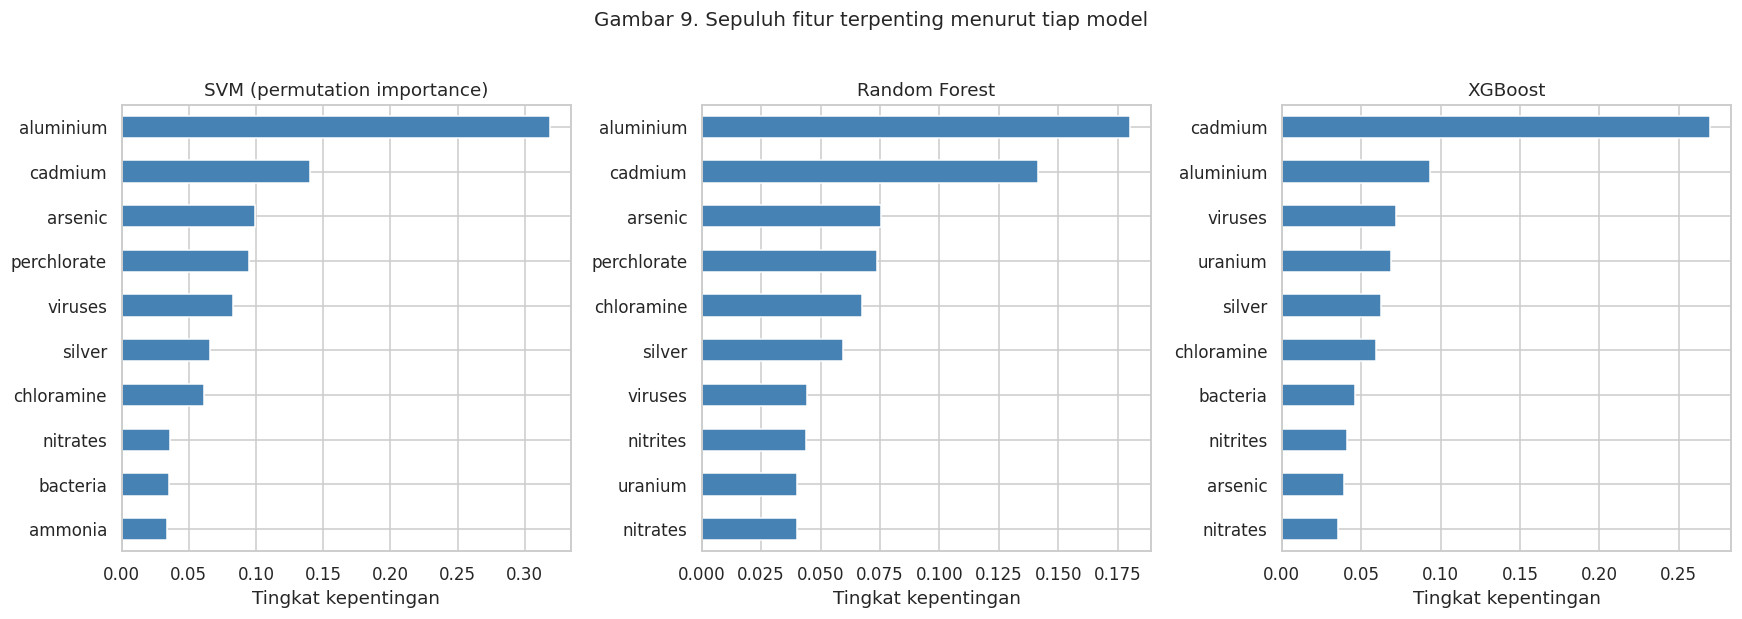

In [ ]:
perm = permutation_importance(searches["SVM"].best_estimator_, X_test, y_test,
                              scoring="f1", n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)

importances = {
    "SVM (permutation importance)": pd.Series(perm.importances_mean, index=features),
    "Random Forest": pd.Series(searches["Random Forest"].best_estimator_.feature_importances_, index=features),
    "XGBoost": pd.Series(searches["XGBoost"].best_estimator_.feature_importances_, index=features),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, (title, imp) in zip(axes, importances.items()):
    imp.sort_values().tail(10).plot(kind="barh", ax=ax, color="steelblue")
    ax.set_title(title)
    ax.set_xlabel("Tingkat kepentingan")
fig.suptitle("Gambar 9. Sepuluh fitur terpenting menurut tiap model", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

**Interpretasi.** Fitur yang muncul di urutan teratas pada ketiga model secara konsisten adalah fitur yang benar-benar membawa informasi untuk membedakan air aman dan tidak aman; fitur yang hanya penting di satu model lebih mungkin mencerminkan karakter algoritmanya. Bandingkan juga dengan korelasi pada Gambar 5: fitur yang penting menurut model tetapi berkorelasi lemah secara linear menunjukkan adanya hubungan non-linear atau interaksi antar fitur.

---
# 5. Model Terbaik dan Kesimpulan

**Kriteria pemilihan model terbaik** (berurutan):

1. **F1 kelas 1** pada data uji (metrik utama).
2. Bila selisih F1 sangat tipis (< 0,01), pertimbangkan **precision** (karena air tidak aman yang lolos paling berbahaya), lalu **PR-AUC**, lalu kesederhanaan dan kecepatan model.

In [ ]:
candidates = comparison.loc[model_names]
best_name = candidates["F1"].idxmax()
best = candidates.loc[best_name]
ranking = candidates.sort_values("F1", ascending=False)
runner_up = ranking.index[1]
gap = ranking["F1"].iloc[0] - ranking["F1"].iloc[1]
base = comparison.loc["Baseline (mayoritas)"]

print("Peringkat model berdasarkan F1 (data uji):")
display(ranking[["F1", "Precision", "Recall", "PR-AUC", "ROC-AUC", "Accuracy"]].round(4))

print(f"MODEL TERBAIK: {best_name}\n")
print(f"- F1 = {best['F1']:.3f}, precision = {best['Precision']:.3f}, recall = {best['Recall']:.3f}, "
      f"PR-AUC = {best['PR-AUC']:.3f}, ROC-AUC = {best['ROC-AUC']:.3f}.")
print(f"- Akurasi {best['Accuracy']:.3f} vs baseline {base['Accuracy']:.3f}; baseline mendapat F1 = {base['F1']:.2f} "
      f"karena tidak pernah memprediksi kelas 1, sehingga akurasi saja tidak menunjukkan kemampuan model.")
print(f"- Selisih F1 dengan peringkat 2 ({runner_up}) = {gap:.3f}.", end=" ")
if gap < 0.01:
    print("Selisihnya sangat tipis, sehingga pilihan juga dapat mempertimbangkan precision, kecepatan, dan interpretabilitas.")
else:
    print("Selisih ini cukup jelas untuk menjadikan model ini pilihan utama.")

cv_gap = best["CV F1 (train)"] - best["F1"]
print(f"- F1 cross-validation = {best['CV F1 (train)']:.3f} vs F1 test = {best['F1']:.3f} (selisih {cv_gap:+.3f}); "
      + ("selisih kecil, model stabil dan tidak terindikasi overfitting berat." if abs(cv_gap) < 0.05
         else "selisih cukup besar, perlu diwaspadai adanya overfitting atau variasi data."))
print(f"- Dari sisi keselamatan: precision {best['Precision']:.3f} berarti sekitar {(1 - best['Precision']) * 100:.1f}% "
      f"sampel yang dinyatakan 'aman' sebenarnya tidak aman.")

Peringkat model berdasarkan F1 (data uji):


,F1,Precision,Recall,PR-AUC,ROC-AUC,Accuracy
XGBoost,0.8539,0.8736,0.8352,0.9384,0.9838,0.9675
Random Forest,0.8000,0.9275,0.7033,0.9120,0.9766,0.9600
SVM,0.6968,0.6753,0.7198,0.7791,0.9581,0.9288


MODEL TERBAIK: XGBoost

- F1 = 0.854, precision = 0.874, recall = 0.835, PR-AUC = 0.938, ROC-AUC = 0.984.
- Akurasi 0.968 vs baseline 0.886; baseline mendapat F1 = 0.00 karena tidak pernah memprediksi kelas 1, sehingga akurasi saja tidak menunjukkan kemampuan model.
- Selisih F1 dengan peringkat 2 (Random Forest) = 0.054. Selisih ini cukup jelas untuk menjadikan model ini pilihan utama.
- F1 cross-validation = 0.859 vs F1 test = 0.854 (selisih +0.005); selisih kecil, model stabil dan tidak terindikasi overfitting berat.
- Dari sisi keselamatan: precision 0.874 berarti sekitar 12.6% sampel yang dinyatakan 'aman' sebenarnya tidak aman.


## Ringkasan temuan dan insight

1. **Kualitas data.** Terdapat 3 baris rusak (`#NUM!`) yang dibuang dan 10 nilai `ammonia` negatif kecil yang dibulatkan ke 0. Tidak ada missing value atau duplikat lain.
2. **Ketidakseimbangan kelas** (sekitar 11% aman) adalah tantangan utama. Accuracy menyesatkan (baseline sudah sekitar 88,6%), sehingga evaluasi bertumpu pada F1, precision, recall, dan PR-AUC untuk kelas 1.
3. **Tidak ada fitur tunggal yang dominan** (korelasi dengan target lemah, maks. sekitar 0,33), sehingga model non-linear yang menangkap kombinasi fitur diperlukan.
4. **Perbandingan model.** Ketiga algoritma dibandingkan secara adil: split stratified yang sama, tuning dengan 5-fold CV pada data latih, penanganan imbalance, dan evaluasi pada data uji yang sama. Model terbaik ditentukan oleh sel di atas berdasarkan hasil aktual.
5. **Implikasi praktis.** Karena air tidak aman yang dinyatakan aman adalah kesalahan paling berbahaya, model ini sebaiknya dipakai sebagai **alat penyaring awal**, bukan pengganti uji laboratorium. Ambang keputusan dapat dinaikkan untuk memprioritaskan precision bila keselamatan lebih penting daripada efisiensi.